# A mask and a beam

So far the mask $M$ and the beam $B$ of the data model

$$d_\nu = M\,B\,(f + a_\nu\, g) + n_\nu$$

were the identity. This notebook uses a non-trivial pair, built with `cmb_scattering.instrument`:

- **Beam:** a Gaussian beam with the width of BICEP3's, FWHM 0.379° = 22.7′ ([BICEP/Keck XV](https://arxiv.org/abs/2110.00482)). The same beam is applied to all three channels here. A beam is diagonal in Fourier space, so it changes nothing in how the samplers work.
- **Mask:** an apodized border mask, one in the middle of the patch and falling to zero at its edges along a cosine ramp. It multiplies the $Q$ and $U$ maps pixel by pixel (`PixelMask`), so it is **not** diagonal in Fourier space and it mixes $E$ and $B$. The samplers then draw the CMB field with a conjugate-gradient Wiener filter instead of the exact mode-by-mode one.

Any `DiagonalEB` can be passed as the beam, and any `DiagonalEB` or `PixelMask` as the mask, to `simulate_data` and to both samplers. Leaving them out gives the identity, as before.

The data set is the PySM d9 map of notebooks 04 and 05 (seed 0, 3 $\mu K$-arcmin). It is then sampled with the scattering posterior with the Gaussian dust prior kept, for 500 iterations. **This is one map and one short chain: an illustration, not a validation.**

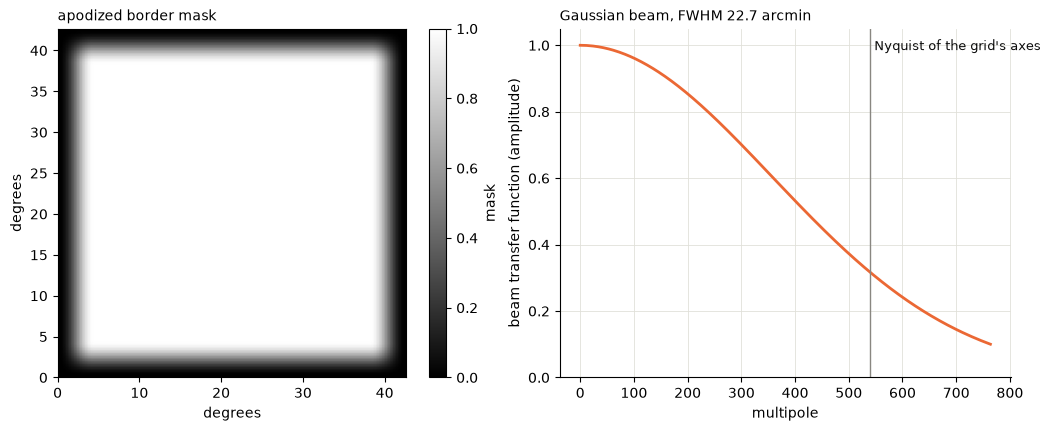

mask: mean = 0.797, mean of its square = 0.754, fraction of pixels where it is one = 0.635
beam at ell = 80: 0.975
beam at ell = 150: 0.915
beam at ell = 540: 0.316
beam at ell = 764: 0.100


In [1]:
import contextlib
import io
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from cmb_lensing.mcmc_diagnostics import autocorrelation, integrated_autocorrelation_time
from cmb_lensing.chain_analysis import product_moments, product_pdf
from cmb_lensing.util import gen_ell_grid
from cmb_scattering.instrument import BICEP3_BEAM_FWHM_ARCMIN, apodized_border_mask, gaussian_beam
from cmb_scattering.simulate_dust import PYSM_DUST, scale_dust_to_frequencies, simulate_data
from cmb_scattering.likelihoods import log_scattering_coefficients
from cmb_scattering.sampler import (DUST_FIELD_NAME, PARAM_BOUNDS, PARAM_ORDER,
                                    sample_scattering_posterior)

#importing cmb_lensing.chain_analysis switches matplotlib to the file-only Agg backend,
#so switch back to drawing figures in the notebook
%matplotlib inline

INK = "#0b0b0b"
MUTED = "#898781"
GRID = "#e1e0d9"
CHAIN_COLOR = "#2a78d6"
BEAM_COLOR = "#eb6834"
DEGREES_PER_ARCMIN = 1 / 60
#multipoles the beam is quoted at: the dust pivot, the top of the tensor signal's range
REFERENCE_ELLS = (80, 150)

def style_axis(ax):
    ax.grid(color = GRID, lw = 0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

nside = 128
theta_pix = 20.0
uk_arcmin = 3.0
map_seed = 0
r_true = 0.03
frequency_exponent_true = 1.49

mask = apodized_border_mask(nside)
beam = gaussian_beam(nside, theta_pix, BICEP3_BEAM_FWHM_ARCMIN)

patch_width_deg = nside * theta_pix * DEGREES_PER_ARCMIN
ell_grid, _ = gen_ell_grid(nside, theta_pix)
ell_grid, beam_matrix = np.asarray(ell_grid), np.asarray(beam.matrix_BB)
nyquist_ell = ell_grid[0].max()
order = np.argsort(ell_grid.ravel())

fig, (mask_ax, beam_ax) = plt.subplots(1, 2, figsize = (11, 4.2), constrained_layout = True)
image = mask_ax.imshow(np.asarray(mask.pixel_map), origin = "lower", cmap = "gray", vmin = 0, vmax = 1,
                       extent = (0, patch_width_deg, 0, patch_width_deg))
fig.colorbar(image, ax = mask_ax, label = "mask")
mask_ax.set_xlabel("degrees")
mask_ax.set_ylabel("degrees")
mask_ax.set_title("apodized border mask", loc = "left", fontsize = 10)
beam_ax.plot(ell_grid.ravel()[order], beam_matrix.ravel()[order], color = BEAM_COLOR, lw = 2)
beam_ax.axvline(nyquist_ell, color = MUTED, lw = 1)
beam_ax.text(nyquist_ell, 0.97, " Nyquist of the grid's axes", color = INK, fontsize = 9, va = "top",
             transform = beam_ax.get_xaxis_transform())
beam_ax.set_xlabel("multipole")
beam_ax.set_ylabel("beam transfer function (amplitude)")
beam_ax.set_ylim(0, 1.05)
beam_ax.set_title(f"Gaussian beam, FWHM {BICEP3_BEAM_FWHM_ARCMIN:.1f} arcmin", loc = "left", fontsize = 10)
style_axis(beam_ax)
plt.show()

mask_map = np.asarray(mask.pixel_map)
print(f"mask: mean = {mask_map.mean():.3f}, mean of its square = {np.mean(mask_map**2):.3f}, "
      f"fraction of pixels where it is one = {np.mean(mask_map == 1):.3f}")
for ell in REFERENCE_ELLS + (nyquist_ell, ell_grid.max()):
    nearest = np.argmin(np.abs(ell_grid.ravel() - ell))
    print(f"beam at ell = {ell_grid.ravel()[nearest]:.0f}: {beam_matrix.ravel()[nearest]:.3f}")

- **The mask** is one over the central 64 % of the pixels and ramps to zero over the outer 10 % of the patch width on each side. The mean of its square, 0.75, is the effective fraction of the patch that is observed.
- **The beam** barely touches the multipoles that carry the tensor signal: it passes 97 % of the amplitude at $\ell = 80$ and 92 % at $\ell = 150$. It removes most of the small scales, passing 32 % at the Nyquist multipole of the grid's axes (540) and 10 % at the grid's corners (764).

## The data, one component at a time

The cell below simulates the data with this mask and beam and rebuilds the 150 GHz channel step by step, in the order of the data model: dust, plus CMB, then the beam, then the mask, then the noise. The noise is added after the mask and is not masked itself.

The PySM dust is made **without** its own edge taper here (`pysm_taper_fraction = 0.0`). In the earlier notebooks the taper made the cut-out of the sky periodic; now the mask takes every component to zero at the edges, so a second taper on the dust alone is not needed.

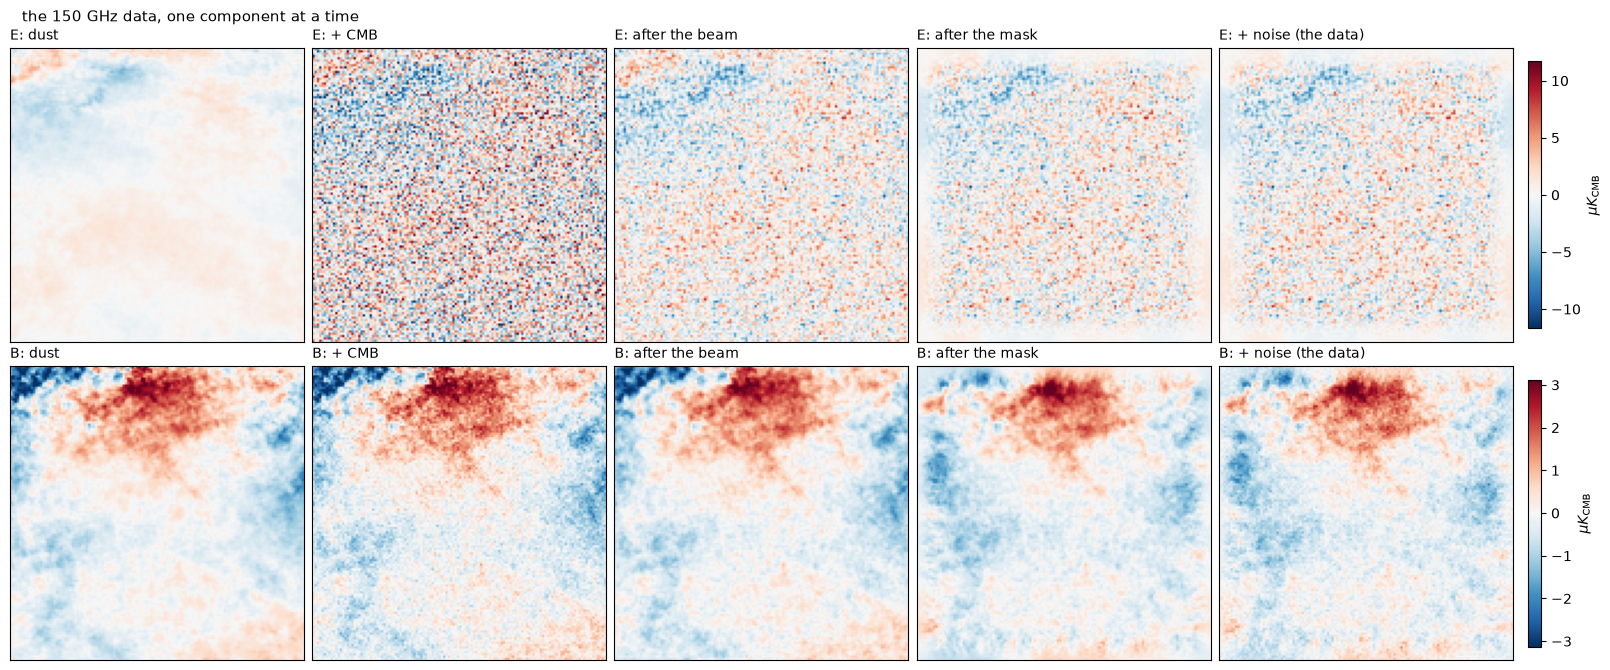

map rms in uK at 150 GHz:
               stage        E        B
                dust    1.011    0.798
               + CMB    4.193    0.841
      after the beam    2.498    0.798
      after the mask    2.157    0.680
  + noise (the data)    2.162    0.695

B-map rms the mask makes out of the E modes alone: 0.272 uK
B-map rms of the masked, beamed CMB B modes:        0.143 uK


In [2]:
#the channel whose maps are shown
SHOWN_FREQUENCY_INDEX = 1
#colour range of each row of maps, as a percentile of |map| over the sky-signal panels
COLOR_PERCENTILE = 99.5

#with a mask on the data the PySM dust needs no taper of its own
sim = simulate_data(nside, theta_pix, map_seed, r_true, frequency_exponent_true,
                    uk_arcmin = uk_arcmin, dust_model = PYSM_DUST, mask = mask, beam = beam,
                    pysm_taper_fraction = 0.0)

def channel(field):
    #the shown channel of a field with a leading frequency axis
    return field.replace(polar_matrix_1 = field.polar_matrix_1[SHOWN_FREQUENCY_INDEX],
                         polar_matrix_2 = field.polar_matrix_2[SHOWN_FREQUENCY_INDEX])

def eb_maps(field):
    return np.fft.irfft2(np.asarray(field.polar_matrix_1)), np.fft.irfft2(np.asarray(field.polar_matrix_2))

#the data of one channel, one step of the data model at a time
dust = channel(scale_dust_to_frequencies(sim["dust_field"], sim["frequency_scaling"]))
sky = dust + sim["cmb_field"]
beamed_sky = beam * sky
masked_sky = mask * beamed_sky
data = channel(sim["data"])
stages = {"dust": dust, "+ CMB": sky, "after the beam": beamed_sky,
          "after the mask": masked_sky, "+ noise (the data)": data}

frequency = float(sim["frequencies"][SHOWN_FREQUENCY_INDEX])
fig, axes = plt.subplots(2, len(stages), figsize = (16, 6.6), constrained_layout = True)
for row, mode in enumerate(("E", "B")):
    limit = np.percentile(np.abs(eb_maps(sky)[row]), COLOR_PERCENTILE)
    for ax, (label, field) in zip(axes[row], stages.items()):
        image = ax.imshow(eb_maps(field)[row], origin = "lower", cmap = "RdBu_r", vmin = -limit, vmax = limit,
                          extent = (0, patch_width_deg, 0, patch_width_deg))
        ax.set_title(f"{mode}: {label}", loc = "left", fontsize = 10)
        ax.set_xticks([])
        ax.set_yticks([])
    fig.colorbar(image, ax = axes[row], label = r"$\mu K_{\rm CMB}$", shrink = 0.9, pad = 0.01)
fig.suptitle(f"the {frequency:.0f} GHz data, one component at a time", x = 0.01, ha = "left", fontsize = 11)
plt.show()

print(f"map rms in uK at {frequency:.0f} GHz:")
print(f"{'stage':>20}  {'E':>7}  {'B':>7}")
for label, field in stages.items():
    e_map, b_map = eb_maps(field)
    print(f"{label:>20}  {e_map.std():7.3f}  {b_map.std():7.3f}")

#E-to-B leakage: mask a sky that has no B modes at all and look at the B map that comes out
e_only_sky = beamed_sky.replace(polar_matrix_2 = 0 * beamed_sky.polar_matrix_2)
leaked_b_map = eb_maps(mask * e_only_sky)[1]
cmb_b_map = eb_maps(mask * (beam * sim["cmb_field"].replace(polar_matrix_1 = 0 * sim["cmb_field"].polar_matrix_1)))[1]
print(f"\nB-map rms the mask makes out of the E modes alone: {leaked_b_map.std():.3f} uK")
print(f"B-map rms of the masked, beamed CMB B modes:        {cmb_b_map.std():.3f} uK")

Each row has one colour scale. The top row is the $E$ map and the bottom row the $B$ map.

- **Dust.** At 150 GHz the dust is the largest part of the $B$ map (0.80 $\mu K$ rms) and a small part of the $E$ map. It is not tapered, so its structure runs up to the edges.
- **+ CMB.** The CMB dominates $E$ (4.2 $\mu K$ rms), with most of its power at small scales, which is why the panel looks like noise at this pixel size. In $B$ the CMB adds little: the rms goes from 0.80 to 0.84 $\mu K$.
- **After the beam.** The small scales are smoothed away. The $E$ rms drops from 4.2 to 2.5 $\mu K$; the $B$ map, which is mostly large-scale dust, barely changes.
- **After the mask.** The maps fade to zero at the border.
- **+ noise.** At 3 $\mu K$-arcmin the noise is 0.15 $\mu K$ per pixel and changes the picture very little. It is the only thing left in the border.

**The mask turns $E$ into $B$.** Masking a sky with no $B$ modes at all gives a $B$ map with an rms of 0.27 $\mu K$, about twice the 0.14 $\mu K$ of the masked CMB $B$ modes that carry $r$. A power-spectrum analysis would have to remove this leakage with a dedicated estimator. Here nothing is done about it: the mask is part of the data model, so the posterior accounts for it.

## Sampling

The chain uses the scattering posterior with the Gaussian dust prior kept (`gaussian_dust_prior = True`), with $\beta_d$ sampled, as in notebook 05. Under the mask:

- **The CMB draw** is a conjugate-gradient solve, since the mask is not diagonal in Fourier space. This is the main cost: an iteration takes about 1.4 s here, against about 0.55 s in notebook 05.
- **The scattering loss is unchanged.** It acts on the sky dust over the whole patch, without mask or beam, and its target is the coefficients of the true dust on the whole patch. The mask and the beam enter the posterior through the data model only. In the border, where the data say nothing, the dust is held by the Gaussian prior and the loss alone.

In [3]:
num_iterations = 500
chain_seed = 1
#iterations dropped from the start of the chain
burn_in = 200
#width of the L2 loss on each log scattering coefficient
scattering_width = 0.1

#the target of the scattering loss: the coefficients of the true dust field on the whole
#patch. The mask enters the posterior through the data model only
target_log_scattering_coefficients = log_scattering_coefficients(sim["dust_field"])

#starting dust parameters, proposal widths and knee bounds as in notebooks 04 and 05
FITTED_DUST_PARAMS = {"dust_amplitude_ee": 28.87, "dust_knee_ee": -0.70,
                      "dust_amplitude_bb": 15.76, "dust_knee_bb": -0.63}
param_init = dict(FITTED_DUST_PARAMS, r = r_true, frequency_exponent = frequency_exponent_true)
proposal_widths = {
    "dust_amplitude_ee": 0.8,
    "dust_amplitude_bb": 0.4,
    "dust_knee_ee": 0.02,
    "dust_knee_bb": 0.02,
    "r": 0.008,
    "frequency_exponent": 0.002,
}
WIDE_KNEE_BOUNDS = (-2.0, 0.0)
param_bounds = dict(PARAM_BOUNDS, dust_knee_ee = WIDE_KNEE_BOUNDS, dust_knee_bb = WIDE_KNEE_BOUNDS)

#capture the per-iteration acceptance printout
with contextlib.redirect_stdout(io.StringIO()):
    sample_histories, acceptance_rates, logposterior_values = sample_scattering_posterior(
        sim["data"], sim["noise_covariance"], sim["scalar_covariance"], sim["tensor_covariance"],
        sim["mask"], sim["beam"], param_init, target_log_scattering_coefficients,
        scattering_width = scattering_width, proposal_widths = proposal_widths,
        param_bounds = param_bounds, gaussian_dust_prior = True,
        num_iterations = num_iterations, seed = chain_seed, frequencies = sim["frequencies"])

print("acceptance rates:")
for name in PARAM_ORDER + [DUST_FIELD_NAME]:
    print(f"{name:>20}  {acceptance_rates[name]:.2f}")

acceptance rates:
   dust_amplitude_ee  0.55
   dust_amplitude_bb  0.62
        dust_knee_ee  0.38
        dust_knee_bb  0.37
                   r  0.51
  frequency_exponent  0.36
          dust_field  0.61


The acceptance rates are close to those without a mask (notebook 05: 0.60 for the dust field's HMC update, 0.33 to 0.54 for the parameters), with the same step size and proposal widths. The HMC mass matrix uses the mask's rms in place of the mask, which is evidently good enough.

## Traces

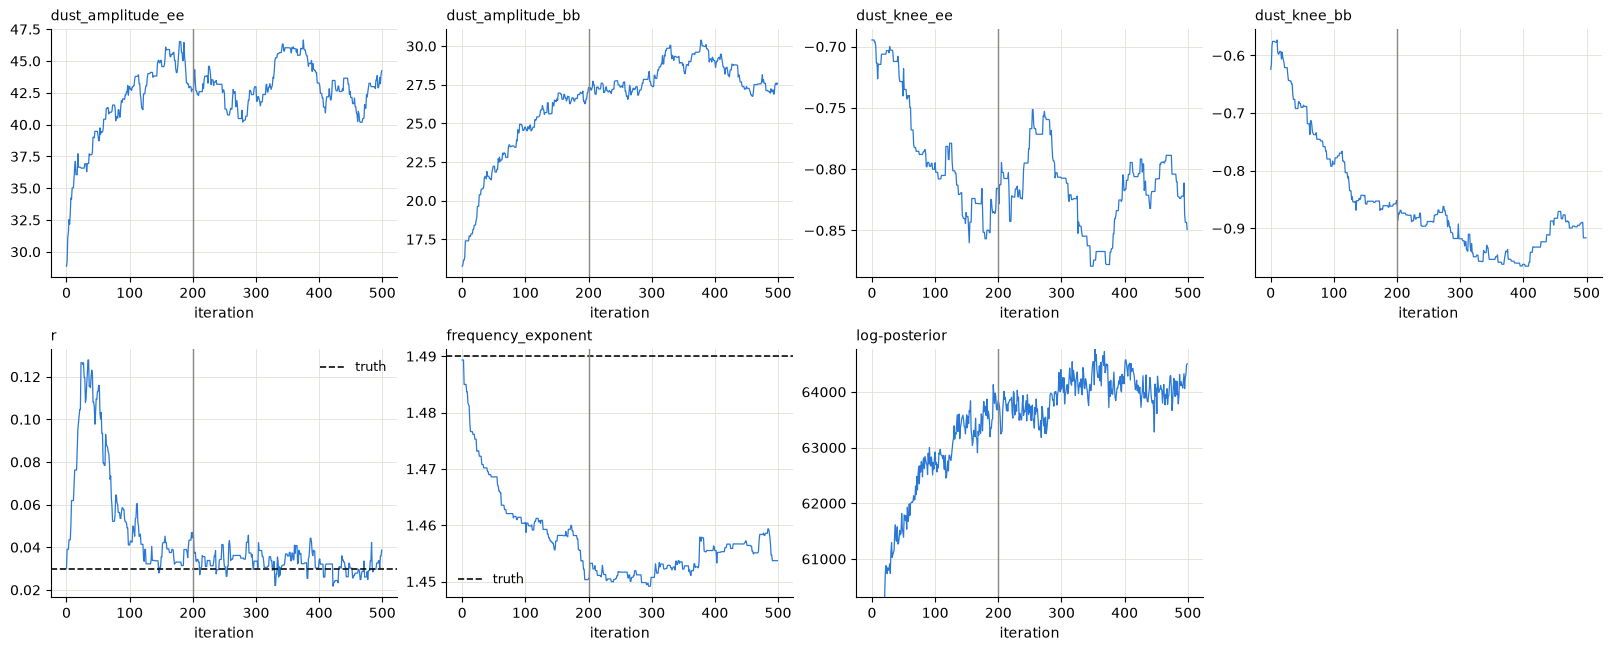

In [4]:
truths = {"r": r_true, "frequency_exponent": frequency_exponent_true}
LOGPOSTERIOR_LABEL = "log-posterior"
traces = dict({name: sample_histories[name] for name in PARAM_ORDER}, **{LOGPOSTERIOR_LABEL: logposterior_values})

fig, axes = plt.subplots(2, 4, figsize = (16, 6.4), constrained_layout = True)
for ax, (name, values) in zip(axes.ravel(), traces.items()):
    ax.plot(values, color = CHAIN_COLOR, lw = 0.9)
    if name in truths:
        ax.axhline(truths[name], color = INK, lw = 1.2, ls = "--", label = "truth")
        ax.legend(frameon = False, fontsize = 9)
    ax.axvline(burn_in, color = MUTED, lw = 1)
    ax.set_title(name, loc = "left", fontsize = 10)
    ax.set_xlabel("iteration")
    ax.ticklabel_format(axis = "y", useOffset = False, style = "plain")
    style_axis(ax)
#the log-posterior starts far below the rest; show the range it has after the first tenth of the burn-in
settled = logposterior_values[burn_in // 10:]
axes.ravel()[len(traces) - 1].set_ylim(settled.min(), settled.max())
axes.ravel()[-1].axis("off")
plt.show()

**The chain needs about 200 iterations to settle, much longer than without a mask.**

- **$r$** jumps to 0.13 in the first 50 iterations and is down to about 0.04 by iteration 150. It then drifts down slowly and scatters about the truth from about iteration 300.
- **The dust parameters** move for the first 200 iterations. The EE amplitude and knee then wander about a level; the BB amplitude and knee are still drifting slowly at the end.
- **$\beta_d$** falls from 1.49 to about 1.450 over the first 250 to 300 iterations and then turns back slightly, to about 1.454 at the end. It has not settled.
- **The log-posterior** rises until about iteration 350 and is roughly level after that.

The likely reason for the long start is the dust field's starting point. It is a crude estimate that replaces the mask by its rms, so it is too bright inside the mask and wrong in the border, and the first CMB draws absorb the mismatch as extra $B$ power. This is a guess from the traces; it was not tested.

## Posteriors after burn-in

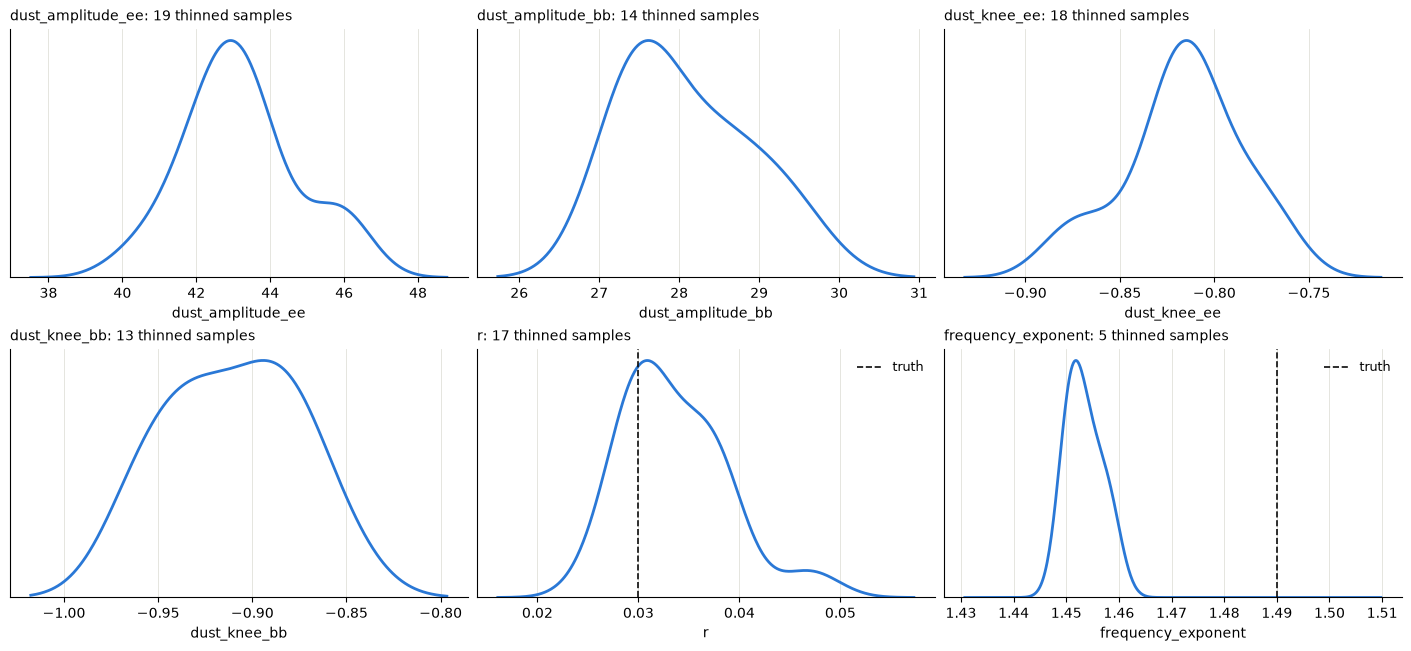

           parameter    truth      mean       std   z-score     IAT  thinned samples
   dust_amplitude_ee        -   43.2023    1.6932         -    16.2               19
   dust_amplitude_bb        -   28.0966    0.9014         -    22.9               14
        dust_knee_ee        -   -0.8166    0.0341         -    17.4               18
        dust_knee_bb        -   -0.9101    0.0394         -    24.5               13
                   r    0.030    0.0336    0.0057     +0.63    18.2               17
  frequency_exponent    1.490    1.4535    0.0038     -9.57    68.9                5


In [5]:
KDE_GRID_POINTS = 400
#how far past the samples' range the density is drawn, as a fraction of that range
KDE_GRID_PADDING = 0.5

def chain_summary(chain, truth = None):
    #IAT, thinned samples, and the KDE's grid, density, mean and std for one parameter chain
    iat = integrated_autocorrelation_time(autocorrelation(chain))
    samples = chain[::max(int(iat), 1)]
    low, high = samples.min(), samples.max()
    if truth is not None:
        low, high = min(low, truth), max(high, truth)
    padding = KDE_GRID_PADDING * (high - low)
    grid = np.linspace(low - padding, high + padding, KDE_GRID_POINTS)
    density = product_pdf([gaussian_kde(samples)(grid)], grid)
    mean, std = product_moments(density, grid)
    return {"iat": iat, "num_samples": len(samples), "grid": grid, "density": density,
            "mean": mean, "std": std}

summaries = {name: chain_summary(sample_histories[name][burn_in:], truths.get(name)) for name in PARAM_ORDER}

fig, axes = plt.subplots(2, 3, figsize = (14, 6.4), constrained_layout = True)
for ax, name in zip(axes.ravel(), PARAM_ORDER):
    summary = summaries[name]
    ax.plot(summary["grid"], summary["density"], color = CHAIN_COLOR, lw = 2)
    if name in truths:
        ax.axvline(truths[name], color = INK, lw = 1.2, ls = "--", label = "truth")
        ax.legend(frameon = False, fontsize = 9)
    ax.set_xlabel(name)
    ax.set_yticks([])
    ax.set_ylim(bottom = 0)
    ax.set_title(f"{name}: {summary['num_samples']} thinned samples", loc = "left", fontsize = 10)
    style_axis(ax)
plt.show()

print(f"{'parameter':>20}  {'truth':>7}  {'mean':>8}  {'std':>8}  {'z-score':>8}  {'IAT':>6}  {'thinned samples':>15}")
for name in PARAM_ORDER:
    summary = summaries[name]
    truth = f"{truths[name]:7.3f}" if name in truths else f"{'-':>7}"
    z_score = f"{(summary['mean'] - truths[name]) / summary['std']:+8.2f}" if name in truths else f"{'-':>8}"
    print(f"{name:>20}  {truth}  {summary['mean']:8.4f}  {summary['std']:8.4f}  {z_score}  "
          f"{summary['iat']:6.1f}  {summary['num_samples']:15d}")

None of the densities is drawn from many independent samples; $r$ has the most use, since it has a true value and scatters about it.

- **$r = 0.0336 \pm 0.0057$**, 0.63 standard deviations above the truth, from 17 thinned samples. The burn-in of 200 still includes the end of the slow descent of $r$ (see the trace), which raises both the mean and the estimated autocorrelation time (18 iterations, against about 6 in the earlier notebooks). The shoulder and the bump near 0.047 are within the noise of that many samples.
- **$\beta_d$ is not a posterior.** Its density is drawn from 5 thinned samples of a chain that is still moving, so the width of 0.0038 and the z-score of $-9.6$ are artefacts. What can be said is that $\beta_d$ sat 0.03 to 0.04 below the truth after burn-in, which is about 0.3 of its prior width.
- **The dust parameters** have 13 to 19 thinned samples each and no true value.

## Compared with the earlier notebooks

All three runs use the same PySM map, noise level and sampler seed. The numbers of notebooks 04 and 05 are read from their stored outputs. This is an anecdotal comparison of single chains of different lengths, not a test.

| | Notebook 04 | Notebook 05 | This notebook |
|---|---|---|---|
| Mask and beam | identity | identity | apodized mask, BICEP3 beam |
| Dust term | scattering loss | scattering loss + Gaussian prior | scattering loss + Gaussian prior |
| $\beta_d$ | fixed at the truth | sampled | sampled |
| Iterations (burn-in) | 1500 (200) | 300 (50) | 500 (200) |
| $r$ (truth 0.03) | $0.0316 \pm 0.0042$ | $0.0317 \pm 0.0050$ | $0.0336 \pm 0.0057$ |
| z-score of $r$ | $+0.39$ | $+0.33$ | $+0.63$ |
| $\beta_d$ during the run (truth 1.49) | n/a | within 0.005 of the truth | down to 1.450, 1.454 at the end |
| HMC acceptance | 0.62 | 0.60 | 0.61 |
| Time per iteration | about 0.47 s | about 0.55 s | about 1.4 s |

**What is the same.**

- **$r$ is consistent.** The mean is 0.002 higher than in notebooks 04 and 05, a third of the posterior width and well inside what 17 samples allow, even though the mask leaks more $E$ into $B$ than the whole CMB $B$ signal.
- **The sampler needs no retuning.** The HMC step size and the proposal widths of the earlier notebooks give the same acceptance rates.
- **No runaway of $\beta_d$**, as in notebook 05.

**What is different.**

- **Burn-in is at least four times longer** (200 to 300 iterations against 50), and an iteration is about 2.5 times slower.
- **The posterior of $r$ may be wider, but the chain cannot tell.** With 75 % of the patch observed, a width larger by about 15 % would be the naive expectation ($1/\sqrt{0.75}$). The width here, 0.0057, is 14 % above notebook 05 (0.0050) and 36 % above notebook 04 (0.0042, from a much longer chain). A width estimated from 17 samples is itself uncertain by about 17 %, and the tail of the burn-in inflates it.
- **$\beta_d$ moves further from the truth** (0.04 against 0.005) and has not come back by the end. Whether this is the slow start working its way out or a small shift caused by the mask or beam cannot be told from 500 iterations.
- **The dust amplitudes are higher** (EE 43.2, BB 28.1, against about 37 and 21 at the end of notebook 05). The dust is not tapered here, which raises its power, so some difference is expected; neither chain had converged dust parameters.

**Not shown here:** any statement about bias. That needs many maps, which is left for a separate test.